# Exploratory Data Analysis (EDA)

## Customer Financial Profile Analysis

### Objective
Explore the cleaned customer financial dataset to understand customer demographics, income, savings, credit scores, loan amounts, employment categories, and recorded risk levels.

### Business Goals
1. Understand the customer portfolio.
2. Analyze financial distributions and summary statistics.
3. Compare financial indicators across customer segments.
4. Examine the distribution of recorded risk categories.
5. Identify patterns, unusual observations, and questions for further investigation.
6. Prepare evidence-based insights for SQL analysis and Power BI.

### Tools
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Data Source
data/processed/Customer_Financial_Profile_Cleaned.csv

### Important Note
EDA describes patterns in the available dataset. Associations do not establish causation, and recorded risk levels are not treated as proof of future loan defaults.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [2]:
# Locate the project root
cwd = Path.cwd()

if cwd.name.lower() == "notebooks":
    project_root = cwd.parent
else:
    project_root = cwd

# Define input and output paths
cleaned_file = (
    project_root
    / "data"
    / "processed"
    / "Customer_Financial_Profile_Cleaned.csv"
)

visualizations_folder = project_root / "visualizations"
reports_folder = project_root / "reports"

# Create output folders if needed
visualizations_folder.mkdir(parents=True, exist_ok=True)
reports_folder.mkdir(parents=True, exist_ok=True)

# Verify that the cleaned CSV exists
print("Project root:", project_root)
print("Cleaned file:", cleaned_file)
print("File exists:", cleaned_file.exists())

if not cleaned_file.exists():
    raise FileNotFoundError(
        "Cleaned CSV not found. Complete Phase 3 first."
    )

# Load the cleaned dataset
df = pd.read_csv(cleaned_file)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Project root: e:\Customer Financial Profile Analysis
Cleaned file: e:\Customer Financial Profile Analysis\data\processed\Customer_Financial_Profile_Cleaned.csv
File exists: True
Dataset loaded successfully!
Rows: 1000
Columns: 9


In [3]:
# Verify the dataset

expected_columns = [
    "Customer_ID",
    "Age",
    "Gender",
    "Annual_Income",
    "Credit_Score",
    "Loan_Amount",
    "Savings_Balance",
    "Employment_Status",
    "Risk_Level"
]

print("Actual columns:", df.columns.tolist())
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["Customer_ID"].duplicated().sum())

missing_columns = [
    col for col in expected_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

print("Dataset structure verified.")

Actual columns: ['Customer_ID', 'Age', 'Gender', 'Annual_Income', 'Credit_Score', 'Loan_Amount', 'Savings_Balance', 'Employment_Status', 'Risk_Level']
Missing values: 0
Duplicate rows: 0
Duplicate customer IDs: 0
Dataset structure verified.


In [5]:
# Create the overall customer summary

numeric_columns = [
    "Age",
    "Annual_Income",
    "Credit_Score",
    "Loan_Amount",
    "Savings_Balance"
]

customer_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Average Age",
        "Average Annual Income",
        "Average Credit Score",
        "Average Loan Amount",
        "Average Savings Balance"
    ],
    "Value": [
        df["Customer_ID"].nunique(),
        round(df["Age"].mean(), 2),
        round(df["Annual_Income"].mean(), 2),
        round(df["Credit_Score"].mean(), 2),
        round(df["Loan_Amount"].mean(), 2),
        round(df["Savings_Balance"].mean(), 2)
    ]
})

display(customer_summary)

customer_summary.to_csv(
    reports_folder / "eda_customer_summary.csv",
    index=False
)

                    Metric     Value
0          Total Customers   1000.00
1              Average Age     43.62
2    Average Annual Income  82136.89
3     Average Credit Score    576.08
4      Average Loan Amount  24185.56
5  Average Savings Balance  98732.28

   Gender  Customer_Count  Percentage
0  Female             523        52.3
1    Male             477        47.7

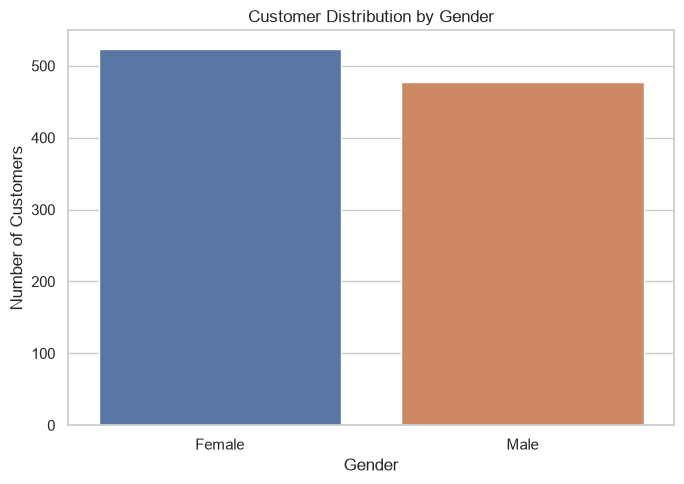

In [7]:
# Analyze customer demographics

# Gender distribution

gender_summary = (
    df["Gender"]
    .value_counts()
    .rename_axis("Gender")
    .reset_index(name="Customer_Count")
)

gender_summary["Percentage"] = (
    gender_summary["Customer_Count"]
    / len(df) * 100
).round(2)

display(gender_summary)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Gender",
    hue="Gender",
    legend=False
)

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    visualizations_folder / "01_gender_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

  Employment_Status  Customer_Count  Percentage
0        Unemployed             336        33.6
1          Employed             334        33.4
2     Self-Employed             330        33.0

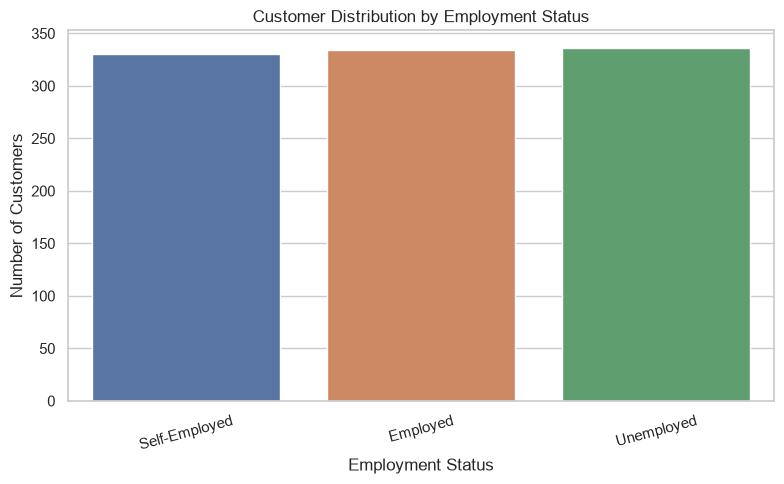

In [8]:
# Employment status distribution

employment_summary = (
    df["Employment_Status"]
    .value_counts()
    .rename_axis("Employment_Status")
    .reset_index(name="Customer_Count")
)

employment_summary["Percentage"] = (
    employment_summary["Customer_Count"]
    / len(df) * 100
).round(2)

display(employment_summary)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Employment_Status",
    hue="Employment_Status",
    legend=False
)

plt.title("Customer Distribution by Employment Status")
plt.xlabel("Employment Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    visualizations_folder / "02_employment_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

  Age_Group  Customer_Count  Percentage
0     18-29             223        22.3
1     30-39             202        20.2
2     40-49             190        19.0
3     50-59             196        19.6
4       60+             189        18.9

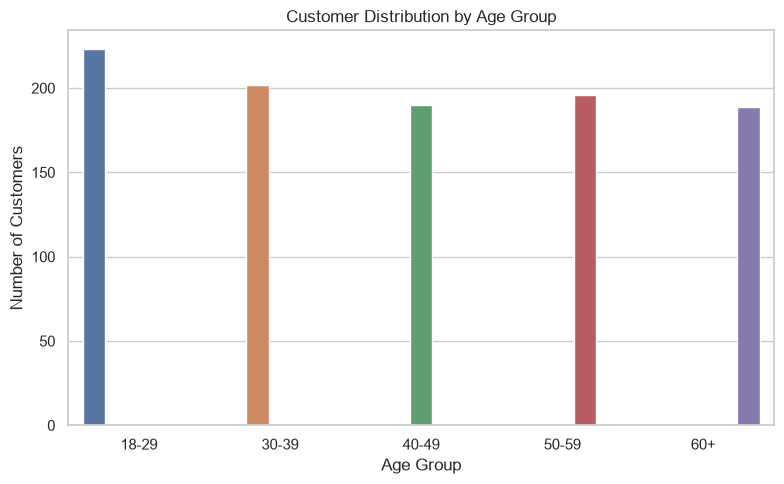

In [9]:
# Create age groups

age_bins = [17, 29, 39, 49, 59, 120]

age_labels = [
    "18-29",
    "30-39",
    "40-49",
    "50-59",
    "60+"
]

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels
)

age_group_summary = (
    df["Age_Group"]
    .value_counts(sort=False)
    .rename_axis("Age_Group")
    .reset_index(name="Customer_Count")
)

age_group_summary["Percentage"] = (
    age_group_summary["Customer_Count"]
    / len(df) * 100
).round(2)

display(age_group_summary)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Age_Group",
    hue="Age_Group",
    order=age_labels,
    legend=False
)

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    visualizations_folder / "03_age_group_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [10]:
# Analyze income, savings, credit scores and loans

# Generate descriptive statistics

financial_summary = df[numeric_columns].describe().T

financial_summary["Median"] = (
    df[numeric_columns].median()
)

display(financial_summary)

financial_summary.to_csv(
    reports_folder / "eda_financial_summary.csv"
)

                  count       mean           std      min       25%       50%  \
Age              1000.0     43.617     14.981414     18.0     31.00      43.0   
Annual_Income    1000.0  82136.893  38911.251316  15012.0  47256.75   82367.5   
Credit_Score     1000.0    576.083    157.206221    302.0    440.75     569.0   
Loan_Amount      1000.0  24185.562  14476.572356    198.0  11348.50   23943.5   
Savings_Balance  1000.0  98732.278  59720.500247    153.0  43070.50  100097.0   

                       75%       max    Median  
Age                  57.00      69.0      43.0  
Annual_Income    116115.00  149971.0   82367.5  
Credit_Score        711.25     850.0     569.0  
Loan_Amount       36844.75   49839.0   23943.5  
Savings_Balance  150810.00  199822.0  100097.0  

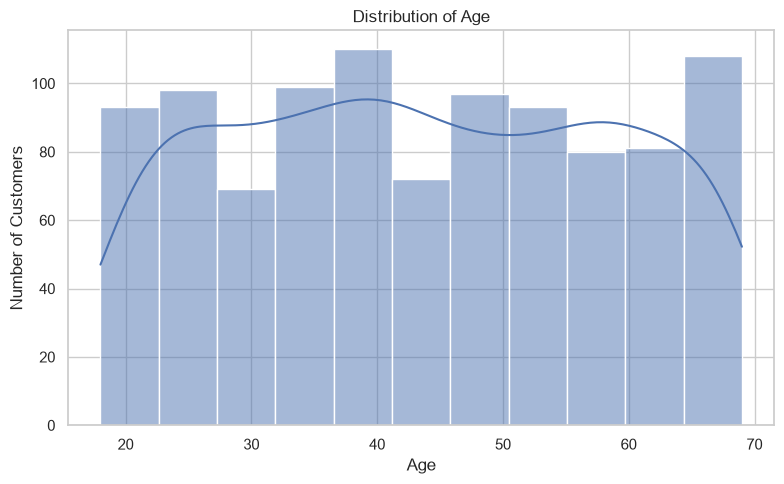

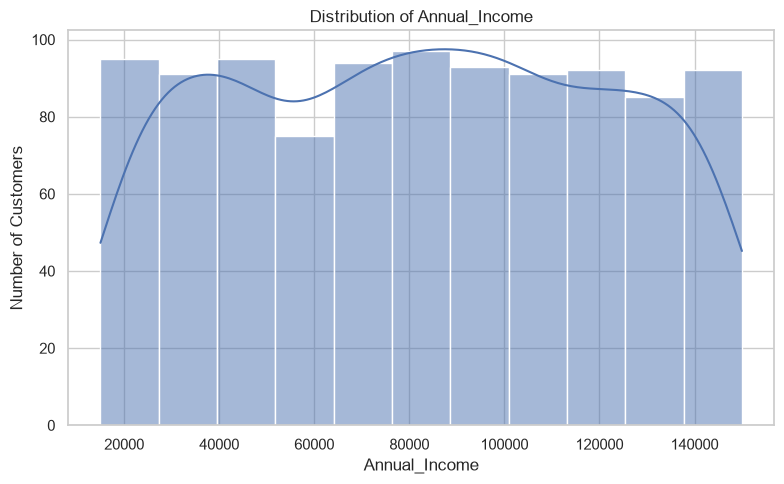

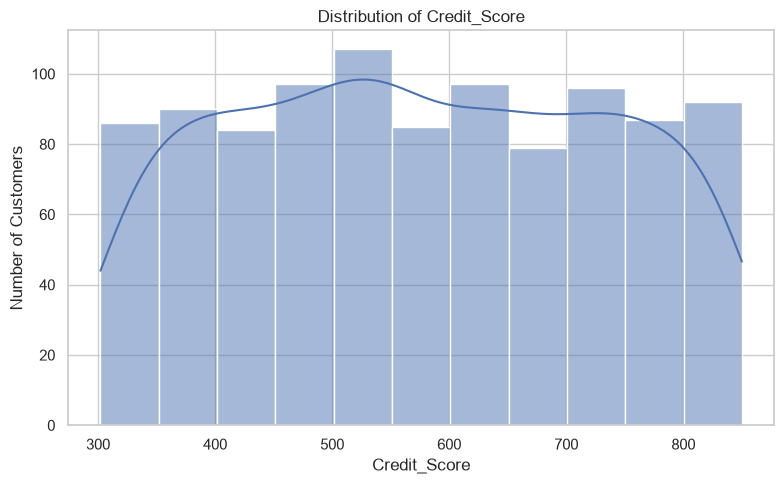

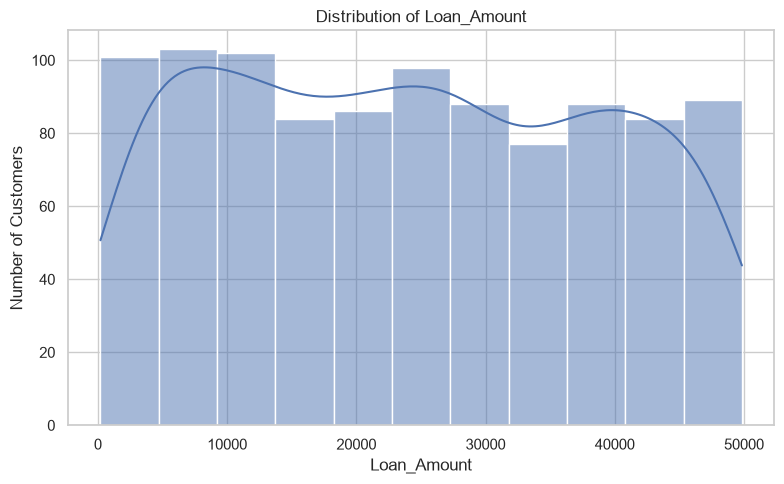

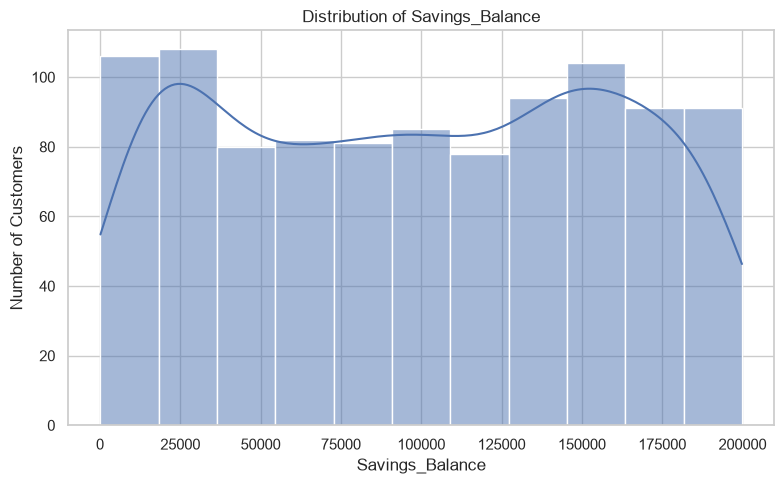

In [11]:
# Plot all five numeric distributions

for column in numeric_columns:
    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=column,
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of Customers")
    plt.tight_layout()

    filename = f"distribution_{column.lower()}.png"

    plt.savefig(
        visualizations_folder / filename,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

In [12]:
# Compare mean and median

mean_median_comparison = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median()
})

mean_median_comparison["Difference"] = (
    mean_median_comparison["Mean"]
    - mean_median_comparison["Median"]
)

display(mean_median_comparison.round(2))

                     Mean    Median  Difference
Age                 43.62      43.0        0.62
Annual_Income    82136.89   82367.5     -230.61
Credit_Score       576.08     569.0        7.08
Loan_Amount      24185.56   23943.5      242.06
Savings_Balance  98732.28  100097.0    -1364.72

  Risk_Level  Customer_Count  Percentage
0     Medium             341        34.1
1       High             334        33.4
2        Low             325        32.5

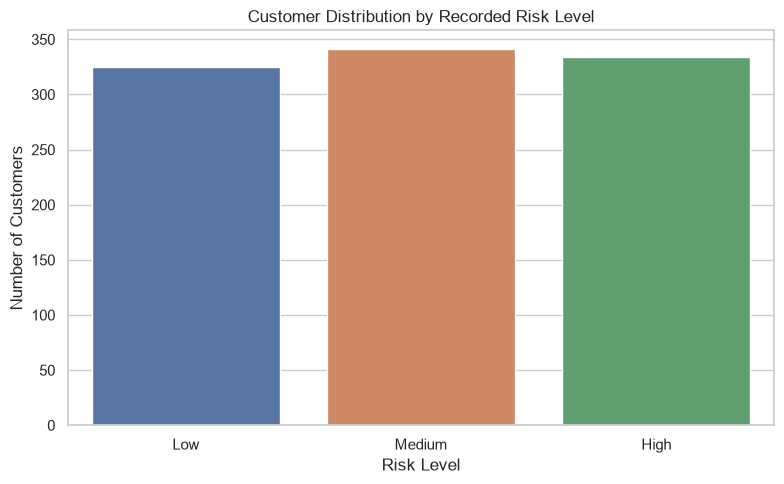

In [13]:
# Analyze the recorded risk categories

# Count and percentage by risk level

risk_summary = (
    df["Risk_Level"]
    .value_counts()
    .rename_axis("Risk_Level")
    .reset_index(name="Customer_Count")
)

risk_summary["Percentage"] = (
    risk_summary["Customer_Count"]
    / len(df) * 100
).round(2)

display(risk_summary)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Risk_Level",
    order=["Low", "Medium", "High"],
    hue="Risk_Level",
    hue_order=["Low", "Medium", "High"],
    legend=False
)

plt.title("Customer Distribution by Recorded Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    visualizations_folder / "09_risk_level_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [14]:
# Compare financial indicators by risk level

risk_financial_summary = (
    df.groupby("Risk_Level", observed=True)[
        [
            "Annual_Income",
            "Credit_Score",
            "Loan_Amount",
            "Savings_Balance"
        ]
    ]
    .agg(["mean", "median", "count"])
    .round(2)
)

display(risk_financial_summary)

           Annual_Income                Credit_Score              Loan_Amount  \
                    mean   median count         mean median count        mean   
Risk_Level                                                                      
High            79032.10  80027.0   334       579.87  580.0   334    24438.43   
Low             83549.11  82968.0   325       584.67  582.0   325    24535.58   
Medium          83832.00  85000.0   341       564.18  549.0   341    23604.29   

                          Savings_Balance                  
             median count            mean    median count  
Risk_Level                                                 
High        24140.5   334        98594.29  101567.0   334  
Low         25038.0   325        98626.94   93616.0   325  
Medium      22769.0   341        98967.83  104059.0   341  

                  Annual_Income                Savings_Balance            \
                           mean   median count            mean    median   
Employment_Status                                                          
Employed               83348.16  86924.5   334        98954.64   97849.5   
Self-Employed          84546.04  85242.5   330        98752.05  100711.5   
Unemployed             78566.71  75144.5   336        98491.82   99117.5   

                        Credit_Score              Loan_Amount                 
                  count         mean median count        mean   median count  
Employment_Status                                                             
Employed            334       589.77  583.5   334    23947.19  24110.0   334  
Self-Employed       330       569.43  553.0   330    23208.88  22708.0   330  
Unemployed          336       569.01  566.0   336    25381.75  24767.0   336  

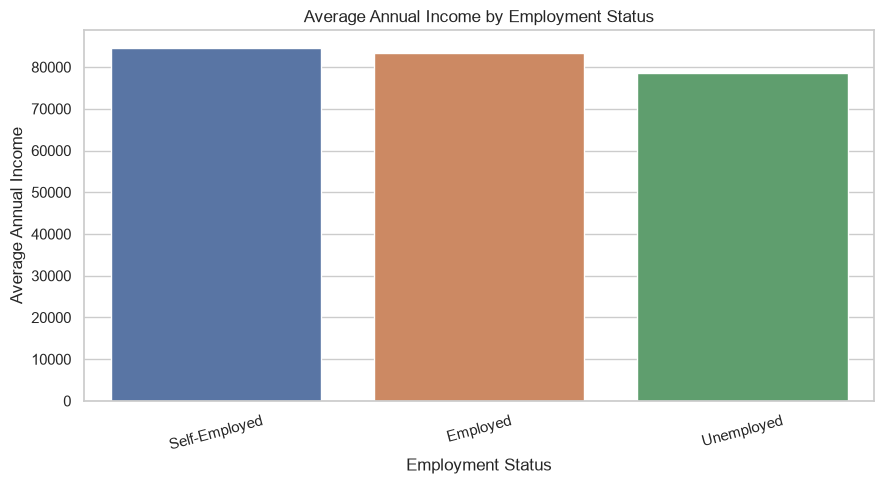

In [15]:
# Compare income and financial indicators by employment

employment_financial_summary = (
    df.groupby("Employment_Status", observed=True)[
        [
            "Annual_Income",
            "Savings_Balance",
            "Credit_Score",
            "Loan_Amount"
        ]
    ]
    .agg(["mean", "median", "count"])
    .round(2)
)

display(employment_financial_summary)

income_by_employment = (
    df.groupby("Employment_Status", observed=True)[
        "Annual_Income"
    ]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=income_by_employment,
    x="Employment_Status",
    y="Annual_Income",
    hue="Employment_Status",
    legend=False
)

plt.title("Average Annual Income by Employment Status")
plt.xlabel("Employment Status")
plt.ylabel("Average Annual Income")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    visualizations_folder / "10_income_by_employment.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

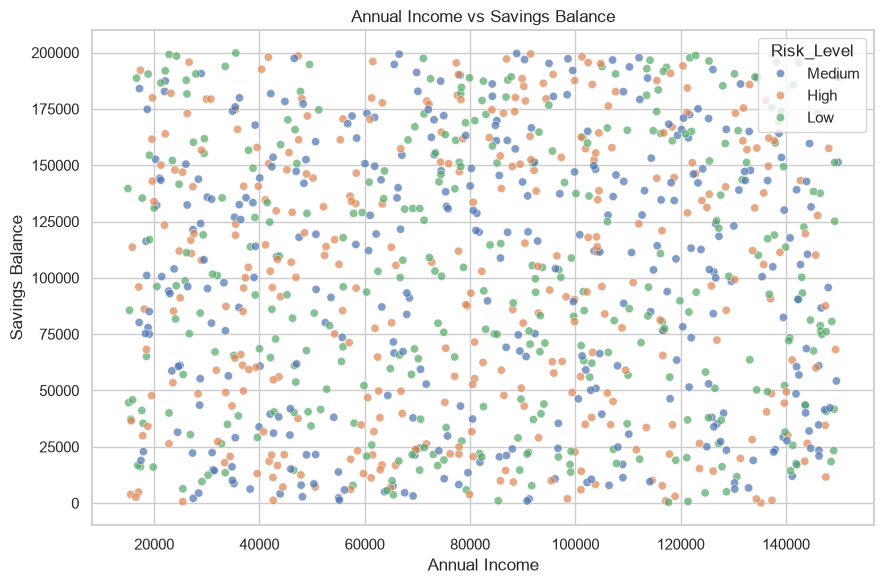

In [16]:
# Explore relationships between financial variables

# Annual income versus savings balance

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Savings_Balance",
    hue="Risk_Level",
    alpha=0.7
)

plt.title("Annual Income vs Savings Balance")
plt.xlabel("Annual Income")
plt.ylabel("Savings Balance")
plt.tight_layout()

plt.savefig(
    visualizations_folder / "11_income_vs_savings.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

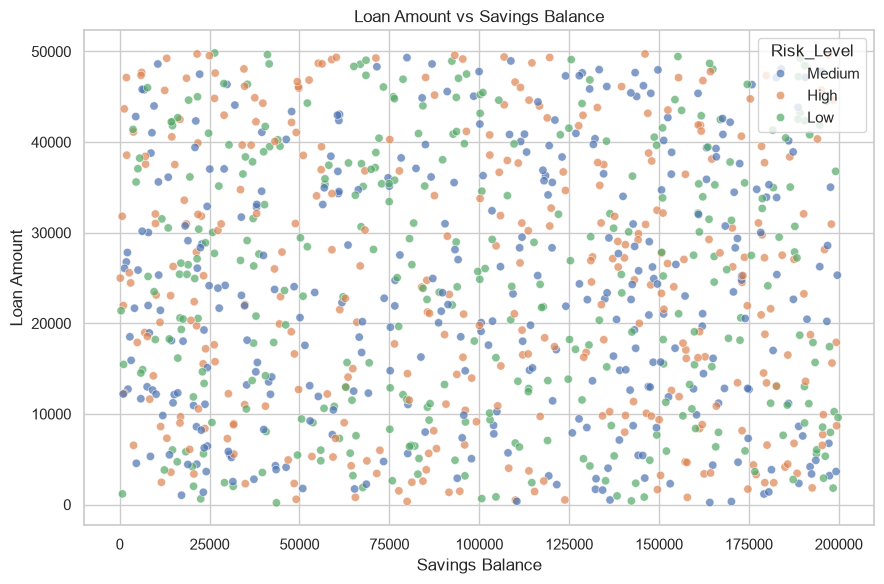

In [17]:
# Loan amount versus savings balance

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Savings_Balance",
    y="Loan_Amount",
    hue="Risk_Level",
    alpha=0.7
)

plt.title("Loan Amount vs Savings Balance")
plt.xlabel("Savings Balance")
plt.ylabel("Loan Amount")
plt.tight_layout()

plt.savefig(
    visualizations_folder / "12_loan_vs_savings.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

                  Age  Annual_Income  Credit_Score  Loan_Amount  \
Age              1.00          -0.02         -0.03        -0.07   
Annual_Income   -0.02           1.00         -0.03        -0.05   
Credit_Score    -0.03          -0.03          1.00         0.06   
Loan_Amount     -0.07          -0.05          0.06         1.00   
Savings_Balance  0.08           0.02         -0.01        -0.03   

                 Savings_Balance  
Age                         0.08  
Annual_Income               0.02  
Credit_Score               -0.01  
Loan_Amount                -0.03  
Savings_Balance             1.00  

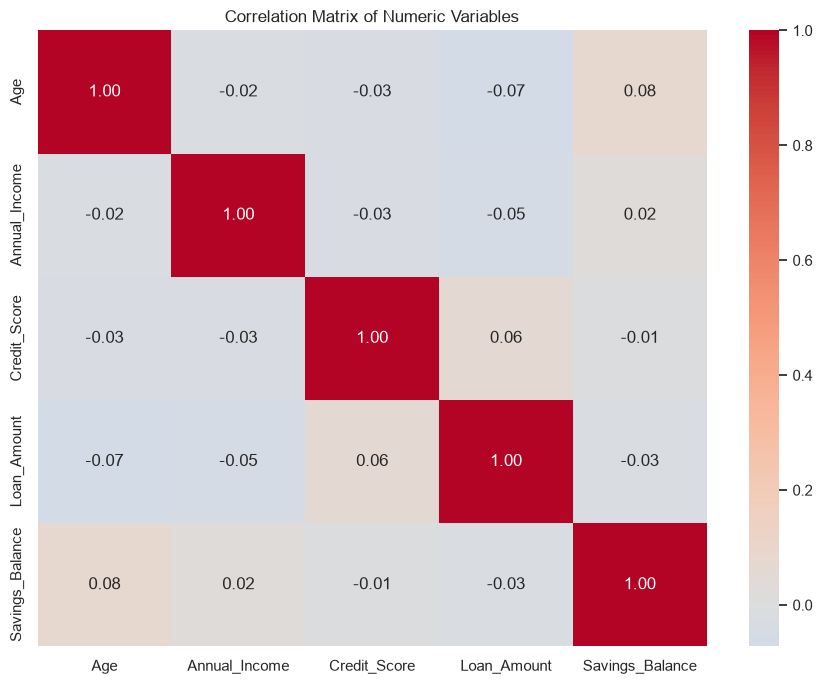

In [18]:
# Calculate correlations

correlation_matrix = df[numeric_columns].corr()

display(correlation_matrix.round(2))

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numeric Variables")
plt.tight_layout()

plt.savefig(
    visualizations_folder / "13_correlation_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [19]:
# Risk level by employment status

risk_by_employment = pd.crosstab(
    df["Employment_Status"],
    df["Risk_Level"],
    margins=True
)

display(risk_by_employment)

risk_by_employment_pct = (
    pd.crosstab(
        df["Employment_Status"],
        df["Risk_Level"],
        normalize="index"
    ) * 100
).round(2)

display(risk_by_employment_pct)

Risk_Level         High  Low  Medium   All
Employment_Status                         
Employed            117  111     106   334
Self-Employed       105  106     119   330
Unemployed          112  108     116   336
All                 334  325     341  1000

Risk_Level          High    Low  Medium
Employment_Status                      
Employed           35.03  33.23   31.74
Self-Employed      31.82  32.12   36.06
Unemployed         33.33  32.14   34.52

In [20]:
# Risk level by age group

risk_by_age = pd.crosstab(
    df["Age_Group"],
    df["Risk_Level"],
    margins=True
)

display(risk_by_age)

risk_by_age_pct = (
    pd.crosstab(
        df["Age_Group"],
        df["Risk_Level"],
        normalize="index"
    ) * 100
).round(2)

display(risk_by_age_pct)

Risk_Level  High  Low  Medium   All
Age_Group                          
18-29         75   70      78   223
30-39         79   64      59   202
40-49         54   60      76   190
50-59         61   68      67   196
60+           65   63      61   189
All          334  325     341  1000

Risk_Level   High    Low  Medium
Age_Group                       
18-29       33.63  31.39   34.98
30-39       39.11  31.68   29.21
40-49       28.42  31.58   40.00
50-59       31.12  34.69   34.18
60+         34.39  33.33   32.28

In [21]:
# Export the cross-tabulation results

risk_by_employment.to_csv(
    reports_folder / "eda_risk_by_employment.csv"
)

risk_by_age.to_csv(
    reports_folder / "eda_risk_by_age_group.csv"
)

risk_financial_summary.to_csv(
    reports_folder / "eda_financials_by_risk.csv"
)

employment_financial_summary.to_csv(
    reports_folder / "eda_financials_by_employment.csv"
)

print("EDA summary tables exported successfully.")

EDA summary tables exported successfully.


## Conclusion — Exploratory Data Analysis (EDA)

### 1. Summary

In this phase, we performed Exploratory Data Analysis (EDA) on the cleaned Customer Financial Profile dataset using Python, Pandas, Matplotlib, and Seaborn.

The objective was to understand customer demographics, financial characteristics, employment patterns, and the distribution of the supplied risk categories.

### 2. EDA Activities Completed

- **Dataset overview:** Reviewed the cleaned dataset structure, dimensions, column names, and data types.
- **Customer KPIs:** Calculated key summary statistics for customer demographics and financial indicators.
- **Demographic analysis:** Examined customer age and gender distributions.
- **Employment analysis:** Compared the number and characteristics of Employed, Self-Employed, and Unemployed customers.
- **Financial distribution analysis:** Investigated annual income, credit scores, loan amounts, and savings balances using descriptive statistics and visualizations.
- **Risk analysis:** Compared customer financial indicators across Low, Medium, and High risk categories.
- **Employment comparison:** Analyzed differences in average income and other financial indicators across employment categories.
- **Relationship analysis:** Explored relationships between annual income and savings balance, as well as loan amount and savings balance.
- **Correlation analysis:** Used a correlation heatmap to examine relationships among numeric variables.
- **Cross-tabulation analysis:** Compared risk categories across employment status and age groups.
- **Visualization and reporting:** Saved relevant charts and summary tables for documentation and future dashboard development.

### 3. Key Business Questions Explored

The analysis investigated the following questions:

1. What are the demographic characteristics of the customers?
2. How are annual income, credit scores, loan amounts, and savings balances distributed?
3. How do financial indicators differ across risk categories?
4. Which employment category has the highest average annual income?
5. Is there an observable relationship between annual income and savings balance?
6. How do loan amounts compare with customer savings balances?
7. Which numeric variables show stronger correlations?
8. How do risk categories vary across employment status and age groups?

### 4. Business Value

The EDA results provide a clearer understanding of the customer population and its financial characteristics. They help identify patterns, differences between customer groups, and relationships that may deserve further investigation.

These findings can support descriptive reporting, business analysis, and the development of an interactive Power BI dashboard.

### 5. Output Files

The analysis outputs are stored in the project folders:

- **Notebook:** `notebooks/03_eda.ipynb`
- **Charts:** `visualizations/`
- **Summary tables and exported results:** `reports/`
- **Cleaned dataset used for analysis:** `data/processed/Customer_Financial_Profile_Cleaned.csv`

### 6. Next Steps

In the next phase, **SQL Business Analysis**, we will:

1. Create and validate the MySQL database schema.
2. Import the cleaned dataset into the `customers` table.
3. Perform basic customer and financial analysis using SQL.
4. Analyze risk categories and employment groups.
5. Use aggregations, subqueries, CTEs, and window functions for advanced analysis.
6. Compare SQL results with Python results to validate consistency.
7. Document the SQL findings and validation results.

### 7. Final Status

**Exploratory Data Analysis (EDA): Completed**

The EDA notebook, visualizations, and summary tables are ready for review, provided all analysis cells executed successfully and the exported files were verified.

**Important limitation:** The `Risk_Level` field is treated as a supplied classification. The observed patterns are descriptive and do not prove causation, predict actual loan defaults, or establish that any customer group is inherently risky.